# 2. Predict timely diagnosis

Use 80% of labeled patients for development and reserve 20% for evaluation. Compare two fixed CatBoost configurations using development out-of-fold AUC. Then evaluate the selected model and create the competition submission.

This notebook calls the phase functions in [src/analysis.py](../src/analysis.py). It performs training; notebook 03 only reads its prediction artifacts. Repeated runs reproduce this existing study and do not create a fresh independent test.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json
from sklearn.metrics import roc_auc_score
from src.analysis import (
    TARGET, TABLES, CANDIDATES, EXCLUDED_COLUMNS,
    read_data, split_data, prepare_features,
    compare_candidates, evaluate_holdout, make_submission,
)

train, test, sample = read_data()
development, holdout = split_data(train)
print("Development patients:", len(development))
print("Holdout patients:", len(holdout))

Development patients: 10324
Holdout patients: 2582


## Prepare model inputs

Exclude patient ID, constant gender and the two extremely sparse novel-treatment columns. Keep numerical NaN, mark categorical missingness Unknown, and add missing indicators for BMI, race and insurance. Diagnosis fields are used for the competition task; this does not establish screening-time availability.

In [2]:
columns = [column for column in train.columns if column not in EXCLUDED_COLUMNS]
x, cats = prepare_features(train, columns)
y = train[TARGET]
print("Prepared features:", x.shape[1])
print("Categorical fields:", cats)
display(pd.DataFrame(CANDIDATES))

Prepared features: 81
Categorical fields: ['patient_race', 'payer_type', 'patient_state', 'breast_cancer_diagnosis_code', 'breast_cancer_diagnosis_desc', 'metastatic_cancer_diagnosis_code', 'Region', 'Division', 'patient_zip3']


,iterations,depth,learning_rate,l2_leaf_reg
0,150,3,0.08,5
1,250,4,0.06,7


## Select using development patients

Each development patient is predicted by a fold model that did not train on that patient. Select by pooled OOF AUC. The holdout is not used to select settings.

In [3]:
params, oof = compare_candidates(train, x, cats, development)
development_auc = roc_auc_score(y.iloc[development], oof)
settings = dict(columns=columns, parameters=params, development_oof_auc=development_auc)
(TABLES / "model_settings.json").write_text(json.dumps({"competition": settings}, indent=2))
print("Selected parameters:", params)
print("Development OOF AUC:", development_auc)
display(pd.read_csv(ROOT / "scores.csv"))

Candidate 0, fold 1: AUC 0.78577


Candidate 0, fold 2: AUC 0.80006


Candidate 0, fold 3: AUC 0.79739


Candidate 0, fold 4: AUC 0.80978


Candidate 0, fold 5: AUC 0.80425


Candidate 1, fold 1: AUC 0.78374


... (2 outputs left out)

Candidate 1, fold 4: AUC 0.81437


Candidate 1, fold 5: AUC 0.80139


Selected parameters: {'iterations': 150, 'depth': 3, 'learning_rate': 0.08, 'l2_leaf_reg': 5}
Development OOF AUC: 0.7990161467976246


,model,candidate,fold,auc,iterations,depth,learning_rate,l2_leaf_reg
0,competition,0,1,0.785769,150,3,0.08,5
1,competition,0,2,0.800063,150,3,0.08,5
2,competition,0,3,0.797395,150,3,0.08,5
3,competition,0,4,0.809780,150,3,0.08,5
4,competition,0,5,0.804250,150,3,0.08,5
5,competition,1,1,0.783736,250,4,0.06,7
6,competition,1,2,0.800343,250,4,0.06,7
7,competition,1,3,0.796053,250,4,0.06,7
8,competition,1,4,0.814369,250,4,0.06,7
9,competition,1,5,0.801395,250,4,0.06,7


## Evaluate the selected model

Fit on development and evaluate the holdout. Save probabilities for the insurance audit so it does not train or select another model. AUC measures ranking; Brier score and the calibration plot describe probability error. Feature importance is not a causal explanation.

,value
development_oof_auc,0.799016
holdout_auc,0.794339
holdout_auc_ci,"[0.7754362142477695, 0.8131217882873116]"
holdout_brier,0.151022
features,81


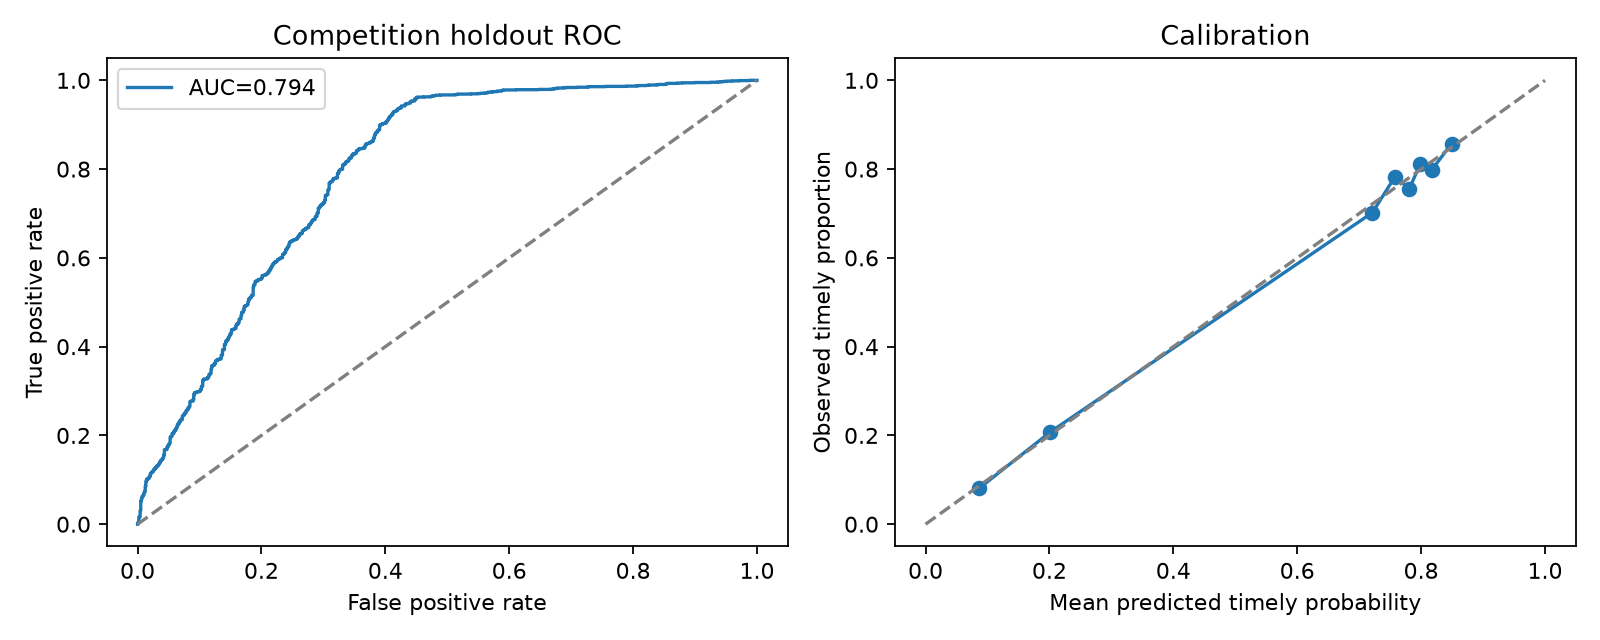

,feature,importance
0,breast_cancer_diagnosis_code,43.372846
1,breast_cancer_diagnosis_desc,41.603578
2,patient_age,3.469848
3,metastatic_cancer_diagnosis_code,1.759937
4,payer_type,0.519540
5,health_uninsured,0.427636
6,education_less_highschool,0.411684
7,income_household_25_to_35,0.390280
8,home_value,0.364084
9,education_highschool,0.350062


In [4]:
summary = evaluate_holdout(train, x, cats, development, holdout, params, oof)
display(pd.Series(summary, name="value").to_frame())
display(Image(filename=str(ROOT / "reports/images/competition_validation.png")))
display(pd.read_csv(TABLES / "competition_importance.csv").head(10))

## Generate the competition output

Train five fold models using all labeled patients and average their test probabilities. The output is timely-diagnosis probability in template order. Local validation AUC is not a Kaggle leaderboard score.

In [5]:
submission = make_submission(train, test, sample, columns, params)
print("Submission rows:", len(submission))
print("Probability range:", submission[TARGET].min(), submission[TARGET].max())
print("Patient IDs match template:", submission.patient_id.equals(sample.patient_id))

Submission model 1/5 completed.


Submission model 2/5 completed.


Submission model 3/5 completed.


Submission model 4/5 completed.


Submission model 5/5 completed.


Submission rows: 5792
Probability range: 0.055484286401510374 0.929937518511684
Patient IDs match template: True
